<a href="https://colab.research.google.com/github/EmptyRain75/mnist-ai-classifier/blob/main/experiments/02_mlp_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MLP Experiments

Add one short study at a time and plan the next after measuring runtime.

| Order | Study | Main question |
|---|---|---|
| 0 | Baseline timing | How expensive is one run? |
| 1 | Input normalization | Does standardization change learning? |
| 2 | Width and depth | What does extra capacity add? |
| 3 | Activation | How does the nonlinearity affect learning? |
| 4 | Initialization | How does the starting scale affect learning? |
| 5 | BatchNorm | Does normalization inside the network help? |
| 6 | SGD versus Adam | How do their chosen configurations compare? |
| 7 | Gradient behavior | What happens to gradients across layers? |

This is the agenda, not a fixed number of training runs. Set the number of configurations and epochs from measured runtimes. Reuse matching controls and collect gradient diagnostics during selected runs where possible.

Use validation results for comparisons; reserve the test set for final evaluation. Keep input normalization separate from BatchNorm. Record one-seed findings as observations about these runs, not universal rankings.

## 0. Baseline and Timing

| Setting | Value |
|---|---|
| Architecture | Flatten → Linear(784,128) → ReLU → Linear(128,10) |
| Parameters | 101,770 |
| Input | Pixels scaled to [0,1], no additional standardization |
| Train / validation | 50,000 / 10,000, seed 42 |
| Optimizer | SGD, no momentum or weight decay |
| Learning rate | 0.1 |
| Batch size | 32 |
| Epochs | 10 |
| Initialization | PyTorch Linear defaults |

This preserves the existing MLP model and training settings. Timing now includes per-epoch validation and uses the available GPU, so runtime is not directly comparable to the earlier source script.

The **MLP experiments have their own two-hour budget**, separate from Softmax. This baseline has a 15-minute run guard. The cumulative guard reserves one minute before the two-hour limit and checks between batches; it cannot interrupt a stalled operation. Downloads, setup, plotting, and idle time are excluded.

Open in a fresh Colab notebook/runtime and select a GPU if available.

In [1]:
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))

# Run this setup cell once. Rerunning it resets the time ledger.
TOTAL_BUDGET_SECONDS = 2 * 60 * 60
STOP_MARGIN_SECONDS = 60
used_run_seconds = 0.0
results = []


Device: cuda
GPU: Tesla T4


In [2]:
full_train = datasets.MNIST(
    root="./data", train=True, download=True,
    transform=transforms.ToTensor(),
)
train_dataset, val_dataset = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
# The test set is deliberately left until final model selection.


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 458kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.4MB/s]

Training images: 50000
Validation images: 10000


### Shared Model and Run Function

Each run starts from fresh parameters and the same seeded training shuffle. The helper records sample-weighted loss, accuracy, and runtime, and saves the checkpoint with the lowest validation loss.

Returned models retain the final epoch's parameters. `result["best_state"]` holds the best checkpoint on CPU, and can be loaded later for final evaluation without retraining. Model and optimizer factories allow later studies to reuse this loop.

In [3]:
class MLP(nn.Module):
    def __init__(self, hidden_sizes=(128,), activation_cls=nn.ReLU,
                 batchnorm=False):
        super().__init__()
        layers = [nn.Flatten()]
        input_size = 784
        for width in hidden_sizes:
            layers.append(nn.Linear(input_size, width))
            if batchnorm:
                layers.append(nn.BatchNorm1d(width))
            layers.append(activation_cls())
            input_size = width
        layers.append(nn.Linear(input_size, 10))
        self.network = nn.Sequential(*layers)

    def forward(self, images):
        return self.network(images)


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def run_experiment(name, lr=0.1, batch_size=32, epochs=10,
                   model_factory=None, optimizer_factory=None,
                   input_transform=None, config=None,
                   max_run_seconds=15 * 60):
    global used_run_seconds
    available = TOTAL_BUDGET_SECONDS - STOP_MARGIN_SECONDS - used_run_seconds
    if available <= 0:
        raise RuntimeError("MLP notebook time budget exhausted.")

    torch.manual_seed(SEED)
    model = (MLP() if model_factory is None else model_factory()).to(device)
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    criterion = nn.CrossEntropyLoss()
    optimizer = (torch.optim.SGD(model.parameters(), lr=lr)
                 if optimizer_factory is None
                 else optimizer_factory(model.parameters(), lr))
    best_loss, best_epoch, best_state = float("inf"), None, None
    history = {"train_loss": [], "val_loss": [], "val_accuracy": [],
               "epoch_seconds": []}

    synchronize()
    started = time.perf_counter()
    deadline = started + min(max_run_seconds, available)
    status = "interrupted"

    def check_time():
        if time.perf_counter() >= deadline:
            raise TimeoutError("Time guard reached; stop and report elapsed time.")

    try:
        for epoch in range(epochs):
            epoch_started = time.perf_counter()
            model.train()
            train_loss = 0.0
            for images, labels in train_loader:
                check_time()
                images, labels = images.to(device), labels.to(device)
                if input_transform is not None:
                    images = input_transform(images)
                optimizer.zero_grad()
                loss = criterion(model(images), labels)
                if not torch.isfinite(loss).item():
                    raise RuntimeError("Non-finite loss: this configuration diverged.")
                loss.backward()
                optimizer.step()
                train_loss += loss.item() * labels.size(0)

            model.eval()
            val_loss, correct = 0.0, 0
            with torch.no_grad():
                for images, labels in val_loader:
                    check_time()
                    images, labels = images.to(device), labels.to(device)
                    if input_transform is not None:
                        images = input_transform(images)
                    logits = model(images)
                    loss = criterion(logits, labels)
                    if not torch.isfinite(loss).item():
                        raise RuntimeError("Non-finite validation loss.")
                    val_loss += loss.item() * labels.size(0)
                    correct += (logits.argmax(1) == labels).sum().item()

            mean_val_loss = val_loss / len(val_dataset)
            if mean_val_loss < best_loss:
                best_loss, best_epoch = mean_val_loss, epoch + 1
                best_state = {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                }
            synchronize()
            epoch_seconds = time.perf_counter() - epoch_started
            history["train_loss"].append(train_loss / len(train_dataset))
            history["val_loss"].append(val_loss / len(val_dataset))
            history["val_accuracy"].append(correct / len(val_dataset))
            history["epoch_seconds"].append(epoch_seconds)
            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"Train loss {history['train_loss'][-1]:.4f} | "
                f"Val loss {history['val_loss'][-1]:.4f} | "
                f"Val acc {history['val_accuracy'][-1]:.2%} | "
                f"{epoch_seconds:.1f} s"
            )
        status = "completed"
    finally:
        synchronize()
        elapsed = time.perf_counter() - started
        used_run_seconds += elapsed
        results.append({
            "name": name, "lr": lr, "batch_size": batch_size,
            "requested_epochs": epochs, "completed_epochs": len(history["train_loss"]),
            "seconds": elapsed, "status": status, "history": history,
            "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "best_epoch": best_epoch, "best_val_loss": best_loss,
            "best_state": best_state, "config": dict(config or {}),
        })
        print(f"Run time (training + validation): {elapsed:.1f} s")
        print(f"Cumulative run time: {used_run_seconds / 60:.1f} / 120 min")

    return model, results[-1]


### Run Once

This run measures the baseline cost. Rerunning the cell trains a fresh model and adds another run to the ledger. No test evaluation occurs here.

In [4]:
baseline_model, baseline = run_experiment(
    name="mlp_baseline",
    lr=0.1,
    batch_size=32,
    epochs=10,
    config={"hidden_sizes": [128], "activation": "ReLU",
            "normalization": "pixels [0,1]", "initialization": "default",
            "batchnorm": False, "optimizer": "SGD"},
)

assert baseline["parameters"] == 101770
print(f"Parameters: {baseline['parameters']:,}")
print(f"Mean time per epoch: {baseline['seconds'] / baseline['completed_epochs']:.1f} s")
print(f"Final validation loss: {baseline['history']['val_loss'][-1]:.4f}")
print(f"Final validation accuracy: {baseline['history']['val_accuracy'][-1]:.2%}")
print(f"Best validation-loss checkpoint: epoch {baseline['best_epoch']}")


Epoch 1/10 | Train loss 0.3700 | Val loss 0.2292 | Val acc 93.49% | 8.6 s
Epoch 2/10 | Train loss 0.1746 | Val loss 0.1634 | Val acc 95.31% | 8.7 s
Epoch 3/10 | Train loss 0.1249 | Val loss 0.1397 | Val acc 95.91% | 8.6 s
Epoch 4/10 | Train loss 0.0966 | Val loss 0.1173 | Val acc 96.43% | 8.0 s
Epoch 5/10 | Train loss 0.0798 | Val loss 0.1038 | Val acc 96.90% | 8.7 s
Epoch 6/10 | Train loss 0.0665 | Val loss 0.0994 | Val acc 97.10% | 8.6 s
Epoch 7/10 | Train loss 0.0561 | Val loss 0.0959 | Val acc 97.13% | 8.0 s
Epoch 8/10 | Train loss 0.0483 | Val loss 0.0944 | Val acc 97.26% | 8.6 s
Epoch 9/10 | Train loss 0.0425 | Val loss 0.0936 | Val acc 97.15% | 8.5 s
Epoch 10/10 | Train loss 0.0370 | Val loss 0.0917 | Val acc 97.18% | 8.3 s
Run time (training + validation): 84.5 s
Cumulative run time: 1.4 / 120 min
Parameters: 101,770
Mean time per epoch: 8.5 s
Final validation loss: 0.0917
Final validation accuracy: 97.18%
Best validation-loss checkpoint: epoch 10


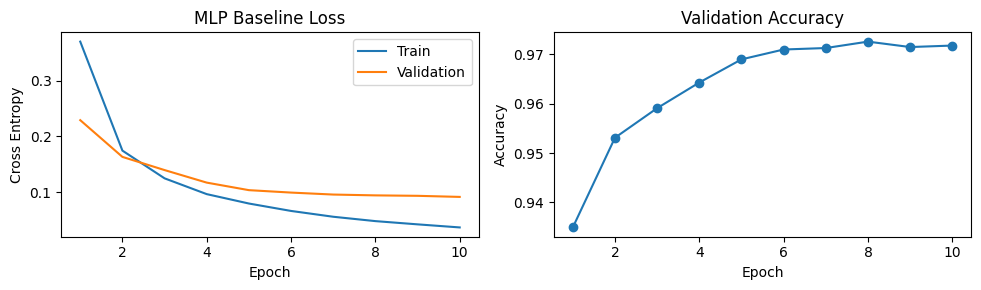

In [5]:
history = baseline["history"]
epoch_numbers = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(epoch_numbers, history["train_loss"], label="Train")
axes[0].plot(epoch_numbers, history["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross Entropy", title="MLP Baseline Loss")
axes[0].legend()
axes[1].plot(epoch_numbers, history["val_accuracy"], marker="o")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Validation Accuracy")
plt.tight_layout()
plt.show()


## 1. Input Normalization

**Question:** Does standardizing inputs improve learning?

Compare:
- Baseline: pixels scaled to [0,1].
- Standardized: (pixel − training mean) / training standard deviation.

Compute one global mean and standard deviation using training
pixels only. Apply those same values to validation inputs.

Keep architecture, initialization, SGD learning rate 0.1,
batch size 32, and ten epochs fixed.

This tests input preprocessing; BatchNorm is a separate study.

In [6]:
stats_loader = DataLoader(
    train_dataset, batch_size=1024, shuffle=False,
)

pixel_sum, pixel_squared_sum, pixel_count = 0.0, 0.0, 0

for images, _ in stats_loader:
    pixels = images.double()
    pixel_sum += pixels.sum().item()
    pixel_squared_sum += pixels.square().sum().item()
    pixel_count += pixels.numel()

input_mean = pixel_sum / pixel_count
input_std = (
    max(pixel_squared_sum / pixel_count - input_mean**2, 0.0)
) ** 0.5

assert input_std > 0
print(f"Training pixel mean: {input_mean:.4f}")
print(f"Training pixel std:  {input_std:.4f}")


def standardize_inputs(images):
    return (images - input_mean) / input_std

Training pixel mean: 0.1307
Training pixel std:  0.3082


In [7]:
standardized_model, standardized = run_experiment(
    name="standardized_inputs",
    lr=0.1,
    batch_size=32,
    epochs=10,
    input_transform=standardize_inputs,
    config={
        **baseline["config"],
        "normalization": "training-set global standardization",
        "input_mean": input_mean,
        "input_std": input_std,
    },
)

normalization_results = [baseline, standardized]

print(
    f"\n{'Input':<18} {'Final loss':>12} {'Final acc':>12}"
    f"{'Best loss':>12} {'Best epoch':>12} {'Time (s)':>12}"
)

for label, result in zip(
    ["Pixels [0,1]", "Standardized"], normalization_results,
):
    h = result["history"]
    print(
        f"{label:<18}"
        f"{h['val_loss'][-1]:>12.4f}"
        f"{h['val_accuracy'][-1]:>12.2%}"
        f"{result['best_val_loss']:>12.4f}"
        f"{result['best_epoch']:>12}"
        f"{result['seconds']:>12.1f}"
    )

print(f"\nCumulative run time: {used_run_seconds / 60:.1f} / 120 min")

Epoch 1/10 | Train loss 0.2318 | Val loss 0.1726 | Val acc 95.00% | 8.9 s
Epoch 2/10 | Train loss 0.1000 | Val loss 0.1041 | Val acc 96.99% | 8.6 s
Epoch 3/10 | Train loss 0.0675 | Val loss 0.1146 | Val acc 96.57% | 8.2 s
Epoch 4/10 | Train loss 0.0484 | Val loss 0.0933 | Val acc 97.06% | 8.9 s
Epoch 5/10 | Train loss 0.0382 | Val loss 0.0920 | Val acc 97.34% | 8.8 s
Epoch 6/10 | Train loss 0.0266 | Val loss 0.0903 | Val acc 97.37% | 8.5 s
Epoch 7/10 | Train loss 0.0189 | Val loss 0.0875 | Val acc 97.47% | 8.6 s
Epoch 8/10 | Train loss 0.0139 | Val loss 0.0877 | Val acc 97.60% | 8.9 s
Epoch 9/10 | Train loss 0.0102 | Val loss 0.0948 | Val acc 97.48% | 8.7 s
Epoch 10/10 | Train loss 0.0060 | Val loss 0.0895 | Val acc 97.66% | 8.3 s
Run time (training + validation): 86.3 s
Cumulative run time: 2.8 / 120 min

Input                Final loss    Final acc   Best loss   Best epoch     Time (s)
Pixels [0,1]            0.0917      97.18%      0.0917          10        84.5
Standardized        

### Normalization Findings

Standardization improved final validation accuracy from
97.18% to 97.66% at the fixed learning rate of 0.1.

The best validation loss improved from 0.0917 to 0.0875.
Training loss decreased faster, while validation loss fluctuated
in later epochs.

Use standardized inputs for the following studies. This result
describes one seed and training configuration.

## 2. Width and Depth

**Question:** What does changing network capacity add?

Compare:
- One hidden layer: 64, 128, or 256 units.
- Two hidden layers: 128 → 128.

Reuse the standardized 128-unit run as the control.

Keep ReLU, default initialization, standardized inputs,
SGD at 0.1, batch size 32, and ten epochs fixed.

Width and depth change both parameter count and computation.
These comparisons do not isolate depth at equal parameter count.

In [8]:
capacity_results = [("128", standardized)]

for hidden_sizes in [(64,), (256,), (128, 128)]:
    label = " → ".join(map(str, hidden_sizes))
    print(f"\nHidden layers: {label}")

    _, result = run_experiment(
        name=f"capacity_{'_'.join(map(str, hidden_sizes))}",
        lr=0.1,
        batch_size=32,
        epochs=10,
        model_factory=lambda sizes=hidden_sizes: MLP(
            hidden_sizes=sizes,
        ),
        input_transform=standardize_inputs,
        config={
            **standardized["config"],
            "hidden_sizes": list(hidden_sizes),
        },
    )
    capacity_results.append((label, result))


Hidden layers: 64
Epoch 1/10 | Train loss 0.2463 | Val loss 0.1736 | Val acc 94.69% | 8.8 s
Epoch 2/10 | Train loss 0.1145 | Val loss 0.1263 | Val acc 96.14% | 8.2 s
Epoch 3/10 | Train loss 0.0848 | Val loss 0.1377 | Val acc 95.83% | 8.7 s
Epoch 4/10 | Train loss 0.0657 | Val loss 0.1021 | Val acc 97.07% | 8.7 s
Epoch 5/10 | Train loss 0.0557 | Val loss 0.1034 | Val acc 96.93% | 8.2 s
Epoch 6/10 | Train loss 0.0458 | Val loss 0.1215 | Val acc 96.47% | 9.3 s
Epoch 7/10 | Train loss 0.0367 | Val loss 0.1201 | Val acc 96.76% | 8.8 s
Epoch 8/10 | Train loss 0.0303 | Val loss 0.1053 | Val acc 97.24% | 8.7 s
Epoch 9/10 | Train loss 0.0277 | Val loss 0.1144 | Val acc 97.10% | 8.3 s
Epoch 10/10 | Train loss 0.0220 | Val loss 0.1145 | Val acc 97.21% | 8.8 s
Run time (training + validation): 86.6 s
Cumulative run time: 4.3 / 120 min

Hidden layers: 256
Epoch 1/10 | Train loss 0.2213 | Val loss 0.1579 | Val acc 95.22% | 8.8 s
Epoch 2/10 | Train loss 0.0901 | Val loss 0.0966 | Val acc 97.05% | 8.

In [9]:
print(
    f"\n{'Hidden layers':<16} {'Parameters':>12}"
    f"{'Final loss':>12} {'Final acc':>12}"
    f"{'Best loss':>12} {'Best epoch':>12} {'Time (s)':>12}"
)

for label, result in capacity_results:
    h = result["history"]
    print(
        f"{label:<16}"
        f"{result['parameters']:>12,}"
        f"{h['val_loss'][-1]:>12.4f}"
        f"{h['val_accuracy'][-1]:>12.2%}"
        f"{result['best_val_loss']:>12.4f}"
        f"{result['best_epoch']:>12}"
        f"{result['seconds']:>12.1f}"
    )

print(f"\nCumulative run time: {used_run_seconds / 60:.1f} / 120 min")


Hidden layers      Parameters  Final loss    Final acc   Best loss   Best epoch     Time (s)
128                  101,770      0.0895      97.66%      0.0875           7        86.3
64                    50,890      0.1145      97.21%      0.1021           4        86.6
256                  203,530      0.0727      97.91%      0.0717           8        86.2
128 → 128            118,282      0.1210      97.42%      0.0983           4        89.6

Cumulative run time: 7.2 / 120 min


### Width and Depth Findings

Increasing width from 128 to 256 improved final validation
accuracy from 97.66% to 97.91%, while doubling parameter count.

The 256-unit model achieved the lowest validation loss: 0.0717.
Measured runtimes were similar on this hardware.

Adding a second 128-unit layer did not improve validation
performance. Its validation loss rose in later epochs while
training loss continued decreasing.

Use one 256-unit hidden layer for the next study. These results
do not establish that deeper networks are generally worse.

## 3. Activation Functions

**Question:** How does the hidden-layer activation affect learning?

Compare:
- ReLU: max(0, x).
- Sigmoid: maps values into (0,1).
- Tanh: maps values into (-1,1).
- GELU: smoothly gates inputs according to their value.

Sigmoid and Tanh can have small derivatives when saturated.
ReLU has zero gradient for negative inputs. GELU provides
a smooth alternative.

Keep width 256, standardized inputs, default initialization,
SGD at 0.1, batch size 32, and ten epochs fixed.

This compares activations under shared settings; it does not
give each activation its own tuned configuration.

In [10]:
relu_control = next(
    result for label, result in capacity_results
    if label == "256"
)
activation_results = [("ReLU", relu_control)]

for name, activation_cls in [
    ("Sigmoid", nn.Sigmoid),
    ("Tanh", nn.Tanh),
    ("GELU", nn.GELU),
]:
    print(f"\nActivation: {name}")

    _, result = run_experiment(
        name=f"activation_{name.lower()}",
        lr=0.1,
        batch_size=32,
        epochs=10,
        model_factory=lambda cls=activation_cls: MLP(
            hidden_sizes=(256,),
            activation_cls=cls,
        ),
        input_transform=standardize_inputs,
        config={
            **relu_control["config"],
            "activation": name,
        },
    )
    activation_results.append((name, result))


Activation: Sigmoid
Epoch 1/10 | Train loss 0.4036 | Val loss 0.2741 | Val acc 92.06% | 9.1 s
Epoch 2/10 | Train loss 0.2175 | Val loss 0.2027 | Val acc 93.98% | 8.3 s
Epoch 3/10 | Train loss 0.1614 | Val loss 0.1643 | Val acc 95.12% | 8.8 s
Epoch 4/10 | Train loss 0.1266 | Val loss 0.1409 | Val acc 95.78% | 8.7 s
Epoch 5/10 | Train loss 0.1039 | Val loss 0.1228 | Val acc 96.42% | 8.2 s
Epoch 6/10 | Train loss 0.0871 | Val loss 0.1133 | Val acc 96.56% | 8.7 s
Epoch 7/10 | Train loss 0.0741 | Val loss 0.1042 | Val acc 96.85% | 8.7 s
Epoch 8/10 | Train loss 0.0642 | Val loss 0.0979 | Val acc 97.02% | 8.2 s
Epoch 9/10 | Train loss 0.0559 | Val loss 0.0960 | Val acc 97.19% | 9.0 s
Epoch 10/10 | Train loss 0.0492 | Val loss 0.0907 | Val acc 97.26% | 8.9 s
Run time (training + validation): 86.6 s
Cumulative run time: 8.7 / 120 min

Activation: Tanh
Epoch 1/10 | Train loss 0.2550 | Val loss 0.1687 | Val acc 95.12% | 8.6 s
Epoch 2/10 | Train loss 0.1114 | Val loss 0.1149 | Val acc 96.45% | 8.

In [11]:
print(
    f"\n{'Activation':<12} {'Train loss':>12}"
    f"{'Val loss':>12} {'Val acc':>12}"
    f"{'Best loss':>12} {'Best epoch':>12} {'Time (s)':>12}"
)

for name, result in activation_results:
    h = result["history"]
    print(
        f"{name:<12}"
        f"{h['train_loss'][-1]:>12.4f}"
        f"{h['val_loss'][-1]:>12.4f}"
        f"{h['val_accuracy'][-1]:>12.2%}"
        f"{result['best_val_loss']:>12.4f}"
        f"{result['best_epoch']:>12}"
        f"{result['seconds']:>12.1f}"
    )

print(f"\nCumulative run time: {used_run_seconds / 60:.1f} / 120 min")


Activation     Train loss    Val loss      Val acc   Best loss   Best epoch     Time (s)
ReLU              0.0029      0.0727      97.91%      0.0717           8        86.2
Sigmoid           0.0492      0.0907      97.26%      0.0907          10        86.6
Tanh              0.0060      0.0765      97.68%      0.0752           8        86.7
GELU              0.0027      0.0765      97.94%      0.0730           8        86.3

Cumulative run time: 11.5 / 120 min


### Activation Findings

ReLU achieved the lowest validation loss: 0.0717.
GELU achieved slightly higher final accuracy: 97.94% versus
97.91%, a difference of only 0.03 percentage points.

Sigmoid learned more slowly and was still improving at epoch 10.
These results alone do not demonstrate vanishing gradients.

Keep ReLU for subsequent studies, using validation loss as
the selection criterion.

## 4. Weight Initialization

**Question:** How does the starting weight distribution affect learning?

Compare the existing default initialization with:

- Small normal: weights sampled from Normal(0, 0.01²).
- Xavier uniform: scale depends on input and output widths.
- He normal: hidden-layer variance is 2 / input width,
  designed for ReLU; use Xavier uniform for the output layer.

Initialization controls the starting scale of activations
and gradients. Very small or large scales can hinder learning.

Keep biases at their default values in every configuration.
Keep the 256-unit ReLU architecture, standardized inputs,
SGD at 0.1, batch size 32, and ten epochs fixed.

In [12]:
def make_initialized_mlp(scheme):
    model = MLP(hidden_sizes=(256,), activation_cls=nn.ReLU)
    linear_layers = [
        layer for layer in model.modules()
        if isinstance(layer, nn.Linear)
    ]

    for i, layer in enumerate(linear_layers):
        is_output = i == len(linear_layers) - 1

        if scheme == "small_normal":
            nn.init.normal_(layer.weight, mean=0.0, std=0.01)

        elif scheme == "xavier":
            nn.init.xavier_uniform_(layer.weight, gain=1.0)

        elif scheme == "he":
            if is_output:
                nn.init.xavier_uniform_(layer.weight, gain=1.0)
            else:
                nn.init.kaiming_normal_(
                    layer.weight,
                    mode="fan_in",
                    nonlinearity="relu",
                )
        else:
            raise ValueError(f"Unknown scheme: {scheme}")

    return model

In [13]:
initialization_results = [("Default", relu_control)]

for label, scheme in [
    ("Small normal", "small_normal"),
    ("Xavier", "xavier"),
    ("He hidden", "he"),
]:
    print(f"\nInitialization: {label}")

    _, result = run_experiment(
        name=f"initialization_{scheme}",
        lr=0.1,
        batch_size=32,
        epochs=10,
        model_factory=lambda s=scheme: make_initialized_mlp(s),
        input_transform=standardize_inputs,
        config={
            **relu_control["config"],
            "initialization": scheme,
        },
    )
    initialization_results.append((label, result))

print(
    f"\n{'Initialization':<16} {'Epoch 1 loss':>14}"
    f"{'Final val loss':>16} {'Final val acc':>15}"
    f"{'Best val loss':>15} {'Time (s)':>12}"
)

for label, result in initialization_results:
    h = result["history"]
    print(
        f"{label:<16}"
        f"{h['train_loss'][0]:>14.4f}"
        f"{h['val_loss'][-1]:>16.4f}"
        f"{h['val_accuracy'][-1]:>15.2%}"
        f"{result['best_val_loss']:>15.4f}"
        f"{result['seconds']:>12.1f}"
    )

print(f"\nCumulative run time: {used_run_seconds / 60:.1f} / 120 min")


Initialization: Small normal
Epoch 1/10 | Train loss 0.2491 | Val loss 0.1592 | Val acc 95.24% | 8.9 s
Epoch 2/10 | Train loss 0.0965 | Val loss 0.1001 | Val acc 96.97% | 8.3 s
Epoch 3/10 | Train loss 0.0627 | Val loss 0.1023 | Val acc 96.79% | 8.7 s
Epoch 4/10 | Train loss 0.0432 | Val loss 0.0814 | Val acc 97.52% | 8.8 s
Epoch 5/10 | Train loss 0.0316 | Val loss 0.0779 | Val acc 97.54% | 8.5 s
Epoch 6/10 | Train loss 0.0208 | Val loss 0.0782 | Val acc 97.72% | 8.6 s
Epoch 7/10 | Train loss 0.0145 | Val loss 0.0799 | Val acc 97.66% | 8.8 s
Epoch 8/10 | Train loss 0.0103 | Val loss 0.0726 | Val acc 97.91% | 8.8 s
Epoch 9/10 | Train loss 0.0061 | Val loss 0.0783 | Val acc 97.83% | 8.9 s
Epoch 10/10 | Train loss 0.0038 | Val loss 0.0739 | Val acc 97.98% | 8.8 s
Run time (training + validation): 87.2 s
Cumulative run time: 13.0 / 120 min

Initialization: Xavier
Epoch 1/10 | Train loss 0.2006 | Val loss 0.1550 | Val acc 95.32% | 8.7 s
Epoch 2/10 | Train loss 0.0820 | Val loss 0.0952 | Val

### Initialization Findings

Default initialization achieved the lowest validation loss:
0.0717, compared with 0.0726 for small normal.

Xavier and He produced lower first-epoch training loss but
did not improve the best validation loss.

All tested schemes learned successfully in this shallow network.
Keep default initialization for subsequent studies.

## 5. Batch Normalization

**Question:** Does normalizing hidden-layer features help?

Compare:
- Control: Linear → ReLU.
- BatchNorm: Linear → BatchNorm → ReLU.

During training, BatchNorm normalizes each hidden feature using
the current mini-batch, then applies learned scale and bias.
It also maintains running statistics for evaluation.

This differs from input standardization: BatchNorm acts on
learned hidden features inside the network.

Keep standardized inputs, width 256, default initialization,
SGD at 0.1, batch size 32, and ten epochs fixed.

BatchNorm adds 512 trainable parameters: one scale and one
bias for each of the 256 hidden features. Running statistics
are buffers, not trainable parameters.

In [14]:
batchnorm_model, batchnorm_result = run_experiment(
    name="batchnorm",
    lr=0.1,
    batch_size=32,
    epochs=10,
    model_factory=lambda: MLP(
        hidden_sizes=(256,),
        activation_cls=nn.ReLU,
        batchnorm=True,
    ),
    input_transform=standardize_inputs,
    config={
        **relu_control["config"],
        "batchnorm": True,
    },
)

batchnorm_results = [
    ("Without BN", relu_control),
    ("With BN", batchnorm_result),
]

print(
    f"\n{'Model':<12} {'Parameters':>12}"
    f"{'Train loss':>12} {'Val loss':>12}"
    f"{'Val acc':>12} {'Best loss':>12}"
    f"{'Best epoch':>12} {'Time (s)':>12}"
)

for label, result in batchnorm_results:
    h = result["history"]
    print(
        f"{label:<12}"
        f"{result['parameters']:>12,}"
        f"{h['train_loss'][-1]:>12.4f}"
        f"{h['val_loss'][-1]:>12.4f}"
        f"{h['val_accuracy'][-1]:>12.2%}"
        f"{result['best_val_loss']:>12.4f}"
        f"{result['best_epoch']:>12}"
        f"{result['seconds']:>12.1f}"
    )

print(f"\nCumulative run time: {used_run_seconds / 60:.1f} / 120 min")

Epoch 1/10 | Train loss 0.2355 | Val loss 0.1351 | Val acc 95.85% | 8.4 s
Epoch 2/10 | Train loss 0.1137 | Val loss 0.1007 | Val acc 96.89% | 9.3 s
Epoch 3/10 | Train loss 0.0831 | Val loss 0.0901 | Val acc 97.29% | 9.1 s
Epoch 4/10 | Train loss 0.0653 | Val loss 0.0794 | Val acc 97.48% | 9.0 s
Epoch 5/10 | Train loss 0.0529 | Val loss 0.0806 | Val acc 97.60% | 8.8 s
Epoch 6/10 | Train loss 0.0449 | Val loss 0.0767 | Val acc 97.67% | 9.1 s
Epoch 7/10 | Train loss 0.0375 | Val loss 0.0758 | Val acc 97.69% | 9.1 s
Epoch 8/10 | Train loss 0.0326 | Val loss 0.0679 | Val acc 98.07% | 8.4 s
Epoch 9/10 | Train loss 0.0272 | Val loss 0.0795 | Val acc 97.54% | 9.2 s
Epoch 10/10 | Train loss 0.0242 | Val loss 0.0733 | Val acc 97.82% | 9.1 s
Run time (training + validation): 89.4 s
Cumulative run time: 17.4 / 120 min

Model          Parameters  Train loss     Val loss     Val acc    Best loss  Best epoch     Time (s)
Without BN       203,530      0.0029      0.0727      97.91%      0.0717        

### BatchNorm Findings

BatchNorm improved the best validation loss from 0.0717
to 0.0679, with 98.07% validation accuracy at epoch 8.

Its final validation loss was slightly worse than the control.
Select saved checkpoints using validation loss rather than
automatically retaining the final epoch.

Keep BatchNorm enabled for the optimizer comparison.

## 6. SGD versus Adam

**Question:** How do these two optimizer configurations compare?

- SGD: learning rate 0.1, no momentum.
- Adam: learning rate 0.001, default beta values.

SGD updates parameters using the current gradient.
Adam tracks moving averages of gradients and squared gradients
to adapt updates for individual parameters.

Keep the model, initialization, standardized inputs, batch size
32, and ten epochs fixed. Neither optimizer uses weight decay.

The learning rates differ deliberately. This compares two
specified configurations, not optimizers independently of
their learning rates or each optimizer's best possible settings.

In [15]:
adam_model, adam_result = run_experiment(
    name="adam_with_batchnorm",
    lr=0.001,
    batch_size=32,
    epochs=10,
    model_factory=lambda: MLP(
        hidden_sizes=(256,),
        activation_cls=nn.ReLU,
        batchnorm=True,
    ),
    optimizer_factory=lambda parameters, lr: torch.optim.Adam(
        parameters,
        lr=lr,
        weight_decay=0.0,
    ),
    input_transform=standardize_inputs,
    config={
        **batchnorm_result["config"],
        "optimizer": "Adam",
    },
)

optimizer_results = [
    ("SGD", batchnorm_result),
    ("Adam", adam_result),
]

print(
    f"\n{'Optimizer':<12} {'LR':>10}"
    f"{'Final loss':>12} {'Final acc':>12}"
    f"{'Best loss':>12} {'Best epoch':>12} {'Time (s)':>12}"
)

for label, result in optimizer_results:
    h = result["history"]
    print(
        f"{label:<12}"
        f"{result['lr']:>10.3f}"
        f"{h['val_loss'][-1]:>12.4f}"
        f"{h['val_accuracy'][-1]:>12.2%}"
        f"{result['best_val_loss']:>12.4f}"
        f"{result['best_epoch']:>12}"
        f"{result['seconds']:>12.1f}"
    )

print(f"\nCumulative run time: {used_run_seconds / 60:.1f} / 120 min")

Epoch 1/10 | Train loss 0.2405 | Val loss 0.1292 | Val acc 96.16% | 9.4 s
Epoch 2/10 | Train loss 0.1137 | Val loss 0.0985 | Val acc 97.06% | 9.1 s
Epoch 3/10 | Train loss 0.0817 | Val loss 0.0897 | Val acc 97.27% | 9.4 s
Epoch 4/10 | Train loss 0.0641 | Val loss 0.0807 | Val acc 97.44% | 9.4 s
Epoch 5/10 | Train loss 0.0527 | Val loss 0.0877 | Val acc 97.23% | 9.7 s
Epoch 6/10 | Train loss 0.0434 | Val loss 0.0800 | Val acc 97.59% | 9.2 s
Epoch 7/10 | Train loss 0.0379 | Val loss 0.0788 | Val acc 97.57% | 9.5 s
Epoch 8/10 | Train loss 0.0319 | Val loss 0.0740 | Val acc 98.02% | 9.5 s
Epoch 9/10 | Train loss 0.0274 | Val loss 0.0876 | Val acc 97.30% | 9.5 s
Epoch 10/10 | Train loss 0.0250 | Val loss 0.0829 | Val acc 97.82% | 9.1 s
Run time (training + validation): 93.8 s
Cumulative run time: 18.9 / 120 min

Optimizer            LR  Final loss    Final acc   Best loss   Best epoch     Time (s)
SGD              0.100      0.0733      97.82%      0.0679           8        89.4
Adam       

### Optimizer Findings

SGD at 0.1 achieved lower best validation loss than Adam at
0.001. Both reached the same final validation accuracy.

Retain the SGD + BatchNorm checkpoint from epoch 8.

## 7. Gradient Behavior

**Question:** How do weight gradients vary across network depth?

Inspect fresh networks:
- ReLU with one hidden layer.
- ReLU, Sigmoid, and Tanh with six hidden layers.

Use width 128, default initialization, standardized inputs,
and the same eight training batches. Deep networks start with
identical linear-layer weights across activation choices.

Calculate each weight matrix's gradient RMS:
sqrt(mean(gradient²)), then average across batches.
RMS helps compare matrices with different parameter counts.

No optimizer updates occur. These are initialization diagnostics,
not measurements of the trained winning model. Gradient sizes
also depend on inputs and loss; they alone do not prove why
an activation performed differently during training.


ReLU, shallow
Hidden 1  : 7.251e-03
Output    : 2.671e-02

ReLU, deep
Hidden 1  : 7.765e-05
Hidden 2  : 7.883e-05
Hidden 3  : 7.698e-05
Hidden 4  : 8.574e-05
Hidden 5  : 1.309e-04
Hidden 6  : 2.333e-04
Output    : 2.330e-03

Sigmoid, deep
Hidden 1  : 1.471e-07
Hidden 2  : 5.224e-07
Hidden 3  : 3.511e-06
Hidden 4  : 2.450e-05
Hidden 5  : 1.726e-04
Hidden 6  : 1.196e-03
Output    : 3.032e-02

Tanh, deep
Hidden 1  : 5.021e-04
Hidden 2  : 4.898e-04
Hidden 3  : 5.041e-04
Hidden 4  : 5.147e-04
Hidden 5  : 5.916e-04
Hidden 6  : 7.805e-04
Output    : 3.927e-03


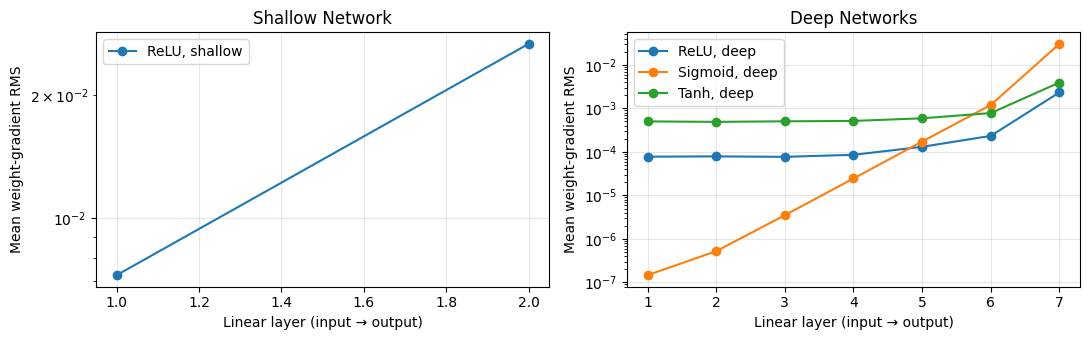


Diagnostic time: 0.2 s
Cumulative run time: 18.9 / 120 min


In [16]:
diagnostic_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=False,
)
diagnostic_batches = []

for images, labels in diagnostic_loader:
    diagnostic_batches.append((
        standardize_inputs(images.to(device)),
        labels.to(device),
    ))
    if len(diagnostic_batches) == 8:
        break

gradient_results = {}
criterion = nn.CrossEntropyLoss()
synchronize()
diagnostic_started = time.perf_counter()

try:
    for label, depth, activation_cls in [
        ("ReLU, shallow", 1, nn.ReLU),
        ("ReLU, deep", 6, nn.ReLU),
        ("Sigmoid, deep", 6, nn.Sigmoid),
        ("Tanh, deep", 6, nn.Tanh),
    ]:
        torch.manual_seed(SEED)
        probe = MLP(
            hidden_sizes=(128,) * depth,
            activation_cls=activation_cls,
        ).to(device)
        probe.train()

        weights = [
            layer.weight for layer in probe.modules()
            if isinstance(layer, nn.Linear)
        ]
        totals = [0.0] * len(weights)

        for images, labels in diagnostic_batches:
            probe.zero_grad(set_to_none=True)
            loss = criterion(probe(images), labels)
            loss.backward()

            for i, weight in enumerate(weights):
                totals[i] += (
                    weight.grad.square().mean().sqrt().item()
                )

        gradient_results[label] = [
            total / len(diagnostic_batches) for total in totals
        ]

        print(f"\n{label}")
        for i, rms in enumerate(gradient_results[label]):
            layer = "Output" if i == len(weights) - 1 else f"Hidden {i + 1}"
            print(f"{layer:<10}: {rms:.3e}")

finally:
    synchronize()
    diagnostic_seconds = time.perf_counter() - diagnostic_started
    used_run_seconds += diagnostic_seconds

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

for label, values in gradient_results.items():
    ax = axes[0] if label == "ReLU, shallow" else axes[1]
    ax.semilogy(range(1, len(values) + 1), values, marker="o", label=label)

for ax, title in zip(axes, ["Shallow Network", "Deep Networks"]):
    ax.set(
        xlabel="Linear layer (input → output)",
        ylabel="Mean weight-gradient RMS",
        title=title,
    )
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nDiagnostic time: {diagnostic_seconds:.1f} s")
print(f"Cumulative run time: {used_run_seconds / 60:.1f} / 120 min")

### Gradient Findings

The six-layer Sigmoid network showed strong gradient attenuation:
gradient RMS decreased from 1.196e-3 in the last hidden layer
to 1.471e-7 in the first.

Deep ReLU also had smaller early-layer gradients. Tanh showed
more uniform hidden-layer gradient magnitudes in this probe.

Activation, depth, and initialization jointly affect gradient
behavior. These initialization diagnostics do not establish
which activation trains best.

## 8. Final Evaluation

Select the lowest validation-loss checkpoint among the training
configurations tested in this notebook:

- One hidden layer with 256 units and ReLU.
- Standardized inputs and BatchNorm.
- Default initialization.
- SGD at learning rate 0.1, batch size 32.
- Saved checkpoint from epoch 8.
- Validation loss 0.0679; validation accuracy 98.07%.

Evaluate this checkpoint on the untouched test set.
No retraining is needed.

In [17]:
selected_result = batchnorm_result

selected_model = MLP(
    hidden_sizes=(256,),
    activation_cls=nn.ReLU,
    batchnorm=True,
).to(device)

# Restores learned parameters AND BatchNorm running statistics.
selected_model.load_state_dict(selected_result["best_state"])
selected_model.eval()

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

criterion = nn.CrossEntropyLoss()
total_loss, correct = 0.0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images = standardize_inputs(images.to(device))
        labels = labels.to(device)

        logits = selected_model(images)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()

best_index = selected_result["best_epoch"] - 1

print(f"Selected epoch: {selected_result['best_epoch']}")
print(f"Parameters: {selected_result['parameters']:,}")
print(f"Validation loss: {selected_result['best_val_loss']:.4f}")
print(
    "Validation accuracy:",
    f"{selected_result['history']['val_accuracy'][best_index]:.2%}",
)
print(f"Test loss: {total_loss / len(test_dataset):.4f}")
print(f"Test accuracy: {correct / len(test_dataset):.2%}")
print(f"Cumulative run time: {used_run_seconds / 60:.1f} / 120 min")

Selected epoch: 8
Parameters: 204,042
Validation loss: 0.0679
Validation accuracy: 98.07%
Test loss: 0.0638
Test accuracy: 97.98%
Cumulative run time: 18.9 / 120 min


## Conclusion

The experiments examined input normalization, network capacity,
activations, initialization, BatchNorm, optimizers, and gradients.

- **Input standardization** improved validation performance.
- **Width:** 256 hidden units outperformed 64 and 128.
  Adding a second 128-unit layer did not help under these settings.
- **Activations:** ReLU and GELU performed similarly;
  ReLU achieved lower best validation loss.
- **Initialization:** Default initialization remained competitive
  and achieved the lowest validation loss among the tested schemes.
- **BatchNorm** improved the best validation checkpoint.
- **Optimizers:** SGD at 0.1 achieved lower best validation loss
  than Adam at 0.001.
- **Gradients:** The fresh deep Sigmoid network showed strong
  attenuation toward earlier layers. This diagnostic did not
  measure gradient behavior throughout training.

### Final Selected Model

| Setting / Metric | Value |
|---|---:|
| Hidden layer | 256 units, ReLU |
| Input preprocessing | Training-set standardization |
| BatchNorm | Enabled |
| Initialization | PyTorch defaults |
| Optimizer | SGD |
| Learning rate | 0.1 |
| Batch size | 32 |
| Selected checkpoint | Epoch 8 |
| Parameters | 204,042 |
| Validation loss | 0.0679 |
| Validation accuracy | 98.07% |
| Test loss | 0.0638 |
| Test accuracy | 97.98% |

Selection used validation loss. The saved checkpoint was then
evaluated on the untouched test set.

Training, validation, and gradient diagnostics took approximately
18.9 minutes. Setup and final test evaluation were excluded.

These sequential, single-seed studies describe the tested
configurations, rather than establishing universally best choices.